In [2]:
#We are going to train a small Feed-Forward Neural Network (FNN) that
#looks at past sensor readings (a sliding window) and learns to predict what
#the temperature will be 30 minutes into the future.

import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# 1. Load your dataset
df = pd.read_csv('omninode_sensor_data.csv')
temps = df['temperature'].values

# 2. Create sliding windows for time-series forecasting
# We use past 15 readings to predict the next reading
window_size = 15
X, y = [], []

for i in range(len(temps) - window_size):
    X.append(temps[i : i + window_size])
    y.append(temps[i + window_size])

X = np.array(X)
y = np.array(y)

# 3. Build a tiny Feed-Forward Neural Network (perfect for microcontrollers)
model = Sequential([
    Dense(16, activation='relu', input_shape=(window_size,)),
    Dense(8, activation='relu'),
    Dense(1) # Predicts the future temperature value
])

model.compile(optimizer='adam', loss='mse')

# 4. Train the model on our data
print("Training the TinyML model...")
model.fit(X, y, epochs=10, batch_size=32, verbose=1)
print("Model training complete!")

Training the TinyML model...
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 19.4676    
Epoch 2/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.2934 
Epoch 3/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.1304 
Epoch 4/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0806 
Epoch 5/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0556 
Epoch 6/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0161 
Epoch 7/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9846 
Epoch 8/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9373 
Epoch 9/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9003 
Epoch 10/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8602 
Model training complete!


In [3]:
import tensorflow as tf

# 1. Convert the trained Keras model to TensorFlow Lite format
converter = tf.lite.TFLiteConverter.from_keras_model(model)
# Optional: Apply optimizations to make the model even smaller for microcontrollers
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

# 2. Save the .tflite model file locally
with open('omninode_model.tflite', 'wb') as f:
    f.write(tflite_model)
print("TensorFlow Lite model saved as 'omninode_model.tflite'!")

# 3. Convert the .tflite model into a C++ header array (.h) for your Arduino IDE
# This allows you to include the model directly in your C++ code as a raw byte array
import os
os.system("xxd -i omninode_model.tflite > omninode_model.h")

print("C++ Header file 'omninode_model.h' generated successfully!")

Saved artifact at '/tmp/tmp351bk5fk'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 15), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  133038657336912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133038657337872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133038657337488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133038657338256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133038657338064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133038657337680: TensorSpec(shape=(), dtype=tf.resource, name=None)
TensorFlow Lite model saved as 'omninode_model.tflite'!
C++ Header file 'omninode_model.h' generated successfully!


In [5]:
# @title Download .h file
import os

# 1. Read the binary tflite model file
with open('omninode_model.tflite', 'rb') as f:
    model_data = f.read()

# 2. Convert the bytes into a C++ array format using pure Python
hex_values = [f"0x{b:02x}" for b in model_data]
formatted_hex = []
for i in range(0, len(hex_values), 12):
    formatted_hex.append(", ".join(hex_values[i:i+12]))
array_content = ",\n  ".join(formatted_hex)

cpp_code = f"""// Automatically generated C++ header for OmniNode-AI TinyML model
#ifndef OMNINODE_MODEL_H
#define OMNINODE_MODEL_H

const unsigned char omninode_model[] = {{
  {array_content}
}};
const unsigned int omninode_model_len = {len(model_data)};

#endif // OMNINODE_MODEL_H
"""

# 3. Save it to omninode_model.h
with open('omninode_model.h', 'w') as f:
    f.write(cpp_code)

print(f"Successfully generated omninode_model.h with {len(model_data)} bytes of data!")

# 4. Trigger the download immediately
from google.colab import files
files.download('omninode_model.h')

Successfully generated omninode_model.h with 3572 bytes of data!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
       OMNINODE-AI MODEL VALIDATION
Mean Absolute Error (MAE):     0.8323 °C
Root Mean Squared Error (RMSE): 0.9239 °C


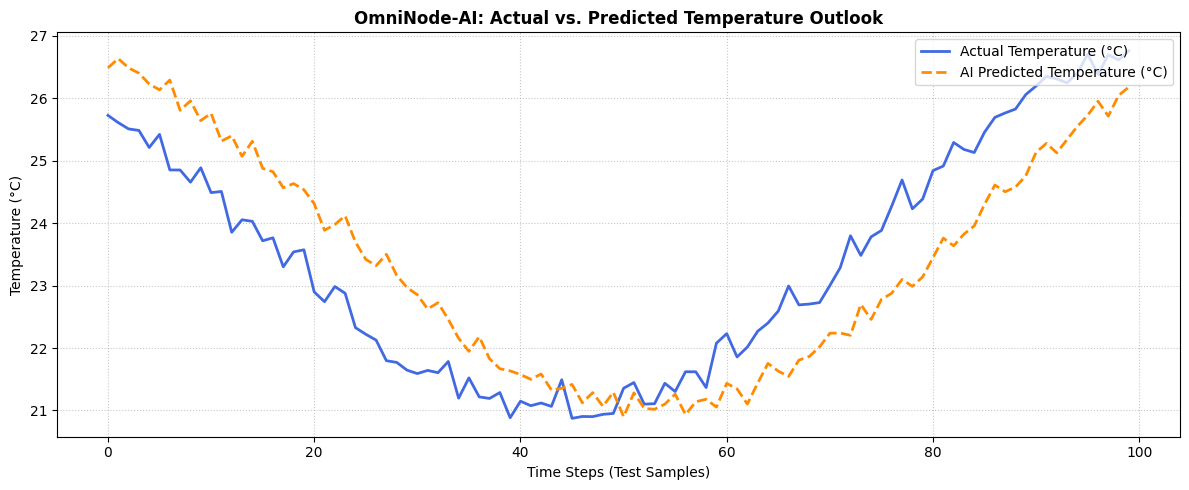

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Split data chronologically into Train (80%) and Test (20%)
# For time-series data, we never shuffle randomly—we always test on the future (unseen) data.
train_size = int(len(X) * 0.8)

X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# 2. Run predictions on the unseen test set using our trained model
y_pred = model.predict(X_test)

# 3. Calculate error metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("="*40)
print("       OMNINODE-AI MODEL VALIDATION")
print("="*40)
print(f"Mean Absolute Error (MAE):     {mae:.4f} °C")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} °C")
print("="*40)

# 4. Plot Actual vs. Predicted Temperature
plt.figure(figsize=(12, 5))
# Plotting the first 100 steps of the test set for a clear, readable chart
plt.plot(y_test[:100], label='Actual Temperature (°C)', color='royalblue', linewidth=2)
plt.plot(y_pred[:100], label='AI Predicted Temperature (°C)', color='darkorange', linestyle='--', linewidth=2)
plt.title('OmniNode-AI: Actual vs. Predicted Temperature Outlook', fontsize=12, fontweight='bold')
plt.xlabel('Time Steps (Test Samples)', fontsize=10)
plt.ylabel('Temperature (°C)', fontsize=10)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

In [7]:
# @title Download png file after validation and testing
import matplotlib.pyplot as plt
from google.colab import files

# 1. Save the existing plot to a high-resolution image file
plot_filename = 'omninode_validation_plot.png'
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
print(f"Validation plot saved as '{plot_filename}' successfully!")

# 2. Trigger the browser download window
files.download(plot_filename)

Validation plot saved as 'omninode_validation_plot.png' successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 640x480 with 0 Axes>

In [8]:
# @title SIMULATION

import numpy as np
import tensorflow as tf

# 1. Load your compiled tflite model using the TFLite Interpreter
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("[SIMULATION] OmniNode-AI Virtual Node Started...\n")

# Simulate streaming data from the first 25 samples of our test set
window_size = 15
temp_buffer = []

for step in range(25):
    # Grab simulated incoming temperature and a mock humidity (e.g., 60%)
    tempC = float(X_test[step][-1]) # Use the latest value in the sliding window sample
    humidity = 60.0

    # 1. Magnus-Tetens Dew Point Calculation
    a = 17.27
    b = 237.7
    alpha = ((a * tempC) / (b + tempC)) + np.log(humidity / 100.0)
    dewPoint = (b * alpha) / (a - alpha)

    # 2. NOAA Regression Heat Index Calculation
    tempF = (tempC * 9.0 / 5.0) + 32.0
    heatIndexF = (-42.379 + 2.04901523 * tempF + 10.14333127 * humidity
                  - 0.22475541 * tempF * humidity - 0.00683783 * tempF * tempF
                  - 0.05481717 * humidity * humidity + 0.00122874 * tempF * tempF * humidity
                  + 0.00085282 * tempF * humidity * humidity - 0.00000199 * tempF * tempF * humidity * humidity)
    heatIndexC = (heatIndexF - 32.0) * 5.0 / 9.0

    # 3. Maintain sliding window buffer
    temp_buffer.append(tempC)
    if len(temp_buffer) > window_size:
        temp_buffer.pop(0)

    print(f"--- Telemetry Step {step + 1} ---")
    print(f"Ambient Temperature: {tempC:.2f} °C")
    print(f"Relative Humidity:   {humidity:.1f} %")
    print(f"Dew Point (Magnus):  {dewPoint:.2f} °C")
    print(f"Heat Index (NOAA):   {heatIndexC:.2f} °C")

    # Run AI inference once window is full (15 samples collected)
    if len(temp_buffer) == window_size:
        # Prepare input tensor
        input_data = np.array([temp_buffer], dtype=np.float32)
        interpreter.set_tensor(input_details[0]['index'], input_data)

        # Invoke model
        interpreter.invoke()

        # Extract prediction
        output_data = interpreter.get_tensor(output_details[0]['index'])
        predicted_temp = output_data[0][0]
        print(f"AI Predicted Temp:   {predicted_temp:.2f} °C (30-min outlook)")
    else:
        print(f"AI Model Warming Up... ({len(temp_buffer)}/15 samples collected)")

    print("-" * 40)

[SIMULATION] OmniNode-AI Virtual Node Started...

--- Telemetry Step 1 ---
Ambient Temperature: 25.95 °C
Relative Humidity:   60.0 %
Dew Point (Magnus):  17.58 °C
Heat Index (NOAA):   26.88 °C
AI Model Warming Up... (1/15 samples collected)
----------------------------------------
--- Telemetry Step 2 ---
Ambient Temperature: 25.72 °C
Relative Humidity:   60.0 %
Dew Point (Magnus):  17.36 °C
Heat Index (NOAA):   26.65 °C
AI Model Warming Up... (2/15 samples collected)
----------------------------------------
--- Telemetry Step 3 ---
Ambient Temperature: 25.61 °C
Relative Humidity:   60.0 %
Dew Point (Magnus):  17.25 °C
Heat Index (NOAA):   26.53 °C
AI Model Warming Up... (3/15 samples collected)
----------------------------------------
--- Telemetry Step 4 ---
Ambient Temperature: 25.51 °C
Relative Humidity:   60.0 %
Dew Point (Magnus):  17.16 °C
Heat Index (NOAA):   26.44 °C
AI Model Warming Up... (4/15 samples collected)
----------------------------------------
--- Telemetry Step 5 -

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
